# Importations des librairies 

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Scikit-learn pour la préparation, la réduction de dimension et le clustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# Prince pour l'Analyse des Correspondances Multiples (ACM)
#import prince


In [16]:
df = pd.read_csv('AB_NYC_2019.csv')
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


# NETTOYAGE ET PRÉPARATION DES DONNÉES

In [17]:
# 1. Gestion des valeurs manquantes
# reviews_per_month : si NaN, c'est qu'il n'y a pas de reviews. On remplace par 0.
df['reviews_per_month'].fillna(0, inplace=True)
print(f"Valeurs manquantes dans 'reviews_per_month' remplacées par 0.")

# On supprime les colonnes qui ne seront pas utiles pour cette analyse
df.drop(['name', 'host_name', 'last_review'], axis=1, inplace=True)
print("Colonnes inutiles ('name', 'host_name', 'last_review') supprimées.")

# 2. Gestion des outliers et erreurs de données
# On observe que certains prix sont à 0, ce qui est une erreur. On les supprime.
df = df[df['price'] > 0]

# Les prix très élevés peuvent fausser l'analyse. On se concentre sur les 99% des offres les moins chères.
price_cap = df['price'].quantile(0.99)
df = df[df['price'] < price_cap]
print(f"Annonces avec un prix de 0 supprimées. Outliers de prix (> {price_cap}$) filtrés.")
print(f"Nouvelle taille du dataset : {df.shape[0]} lignes.")

# 3. Feature Engineering
# Création d'une variable "log_price" pour normaliser la distribution du prix
df['log_price'] = np.log1p(df['price'])
print("Variable 'log_price' créée pour une meilleure distribution.")

# On ne garde que les colonnes utiles pour la suite
df_clean = df[['id', 'neighbourhood_group', 'latitude', 'longitude', 'room_type', 'price', 'log_price', 
               'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 
               'availability_365']].copy()

Valeurs manquantes dans 'reviews_per_month' remplacées par 0.
Colonnes inutiles ('name', 'host_name', 'last_review') supprimées.
Annonces avec un prix de 0 supprimées. Outliers de prix (> 799.0$) filtrés.
Nouvelle taille du dataset : 48392 lignes.
Variable 'log_price' créée pour une meilleure distribution.


/var/folders/hv/y00c8cl91z34xlwn9xbh5cfr0000gn/T/ipykernel_33520/1954483822.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['reviews_per_month'].fillna(0, inplace=True)


# ANALYSE EXPLORATOIRE ET TESTS D'HYPOTHÈSES

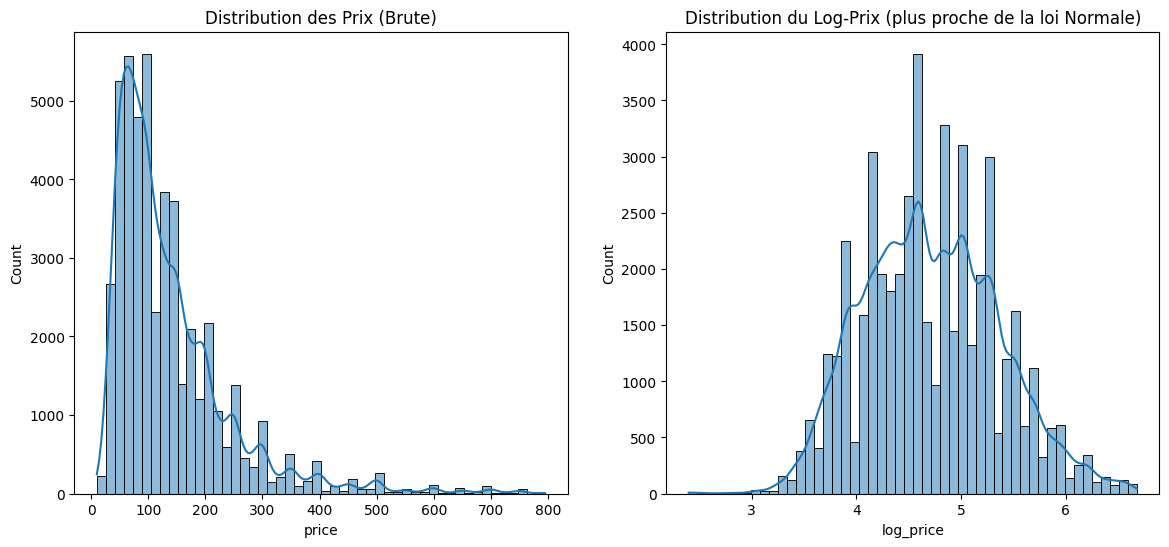

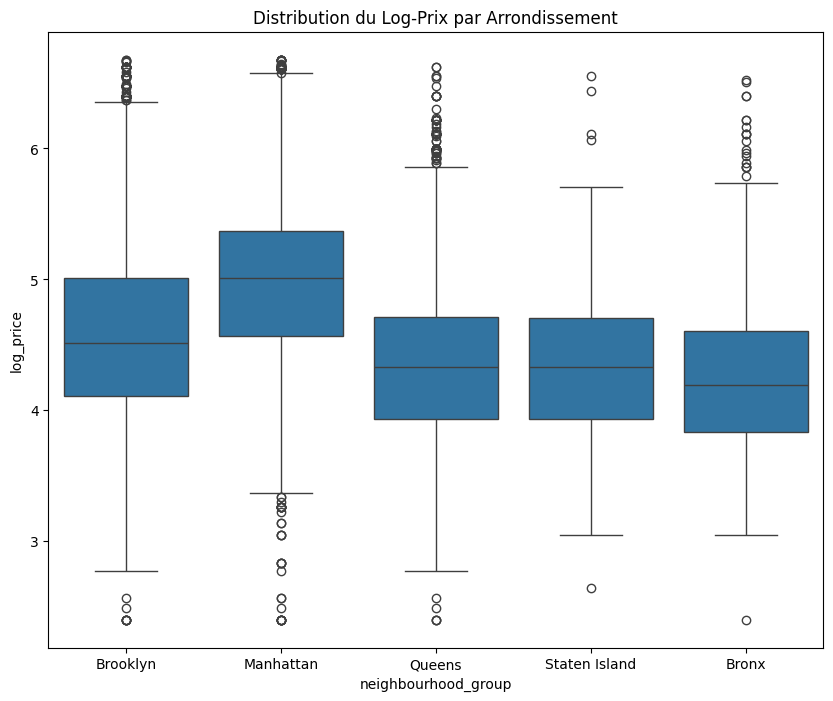

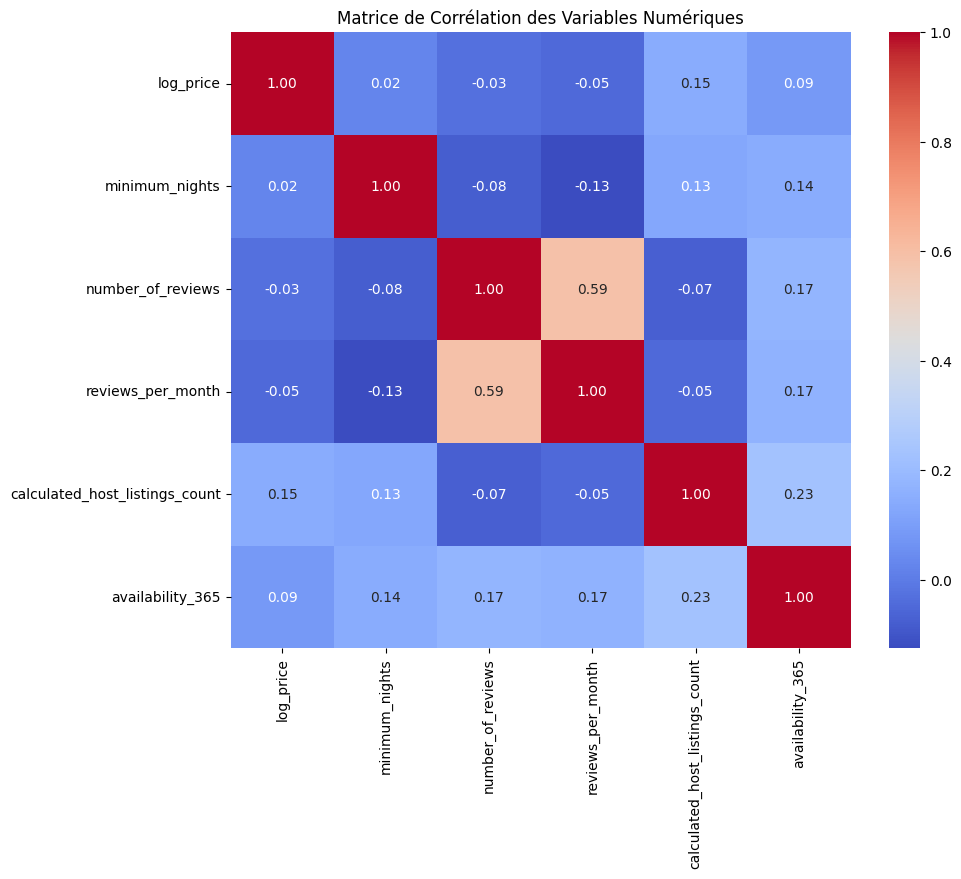

--- T-test (Manhattan vs Brooklyn) ---
P-valeur: 0.00000
Conclusion : On rejette l'hypothèse nulle. Les prix moyens sont significativement différents.

--- Test du Chi-carré (Arrondissement vs Type de chambre) ---
P-valeur: 0.00000
Conclusion : On rejette l'hypothèse nulle. Il y a une association significative entre les variables.


In [18]:
# 1. Distribution du prix
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
sns.histplot(df_clean['price'], kde=True, bins=50)
plt.title('Distribution des Prix (Brute)')
plt.subplot(1, 2, 2)
sns.histplot(df_clean['log_price'], kde=True, bins=50)
plt.title('Distribution du Log-Prix (plus proche de la loi Normale)')
plt.show()

# 2. Analyse bivariée
plt.figure(figsize=(10, 8))
sns.boxplot(data=df_clean, x='neighbourhood_group', y='log_price')
plt.title('Distribution du Log-Prix par Arrondissement')
plt.show()

# 3. Matrice de corrélation des variables quantitatives
numerical_cols = ['log_price', 'minimum_nights', 'number_of_reviews', 
                  'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
corr_matrix = df_clean[numerical_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matrice de Corrélation des Variables Numériques')
plt.show()


# 4. Tests d'Hypothèses
# Test 1: T-test de Student - Le prix moyen à Manhattan est-il différent de celui de Brooklyn ?
manhattan_prices = df_clean[df_clean['neighbourhood_group'] == 'Manhattan']['log_price']
brooklyn_prices = df_clean[df_clean['neighbourhood_group'] == 'Brooklyn']['log_price']
t_stat, p_value = stats.ttest_ind(manhattan_prices, brooklyn_prices, equal_var=False)
print(f"--- T-test (Manhattan vs Brooklyn) ---")
print(f"P-valeur: {p_value:.5f}")
if p_value < 0.05:
    print("Conclusion : On rejette l'hypothèse nulle. Les prix moyens sont significativement différents.")
else:
    print("Conclusion : On ne peut pas rejeter l'hypothèse nulle.")

# Test 2: Test du Chi-carré - Y a-t-il une dépendance entre le type de chambre et l'arrondissement ?
contingency_table = pd.crosstab(df_clean['neighbourhood_group'], df_clean['room_type'])
chi2, p_value, _, _ = stats.chi2_contingency(contingency_table)
print(f"\n--- Test du Chi-carré (Arrondissement vs Type de chambre) ---")
print(f"P-valeur: {p_value:.5f}")
if p_value < 0.05:
    print("Conclusion : On rejette l'hypothèse nulle. Il y a une association significative entre les variables.")
else:
    print("Conclusion : On ne peut pas rejeter l'hypothèse nulle.")


# RÉDUCTION DE DIMENSION


--- Étape 4: Réduction de Dimension ---
--- Lancement de l'ACP ---


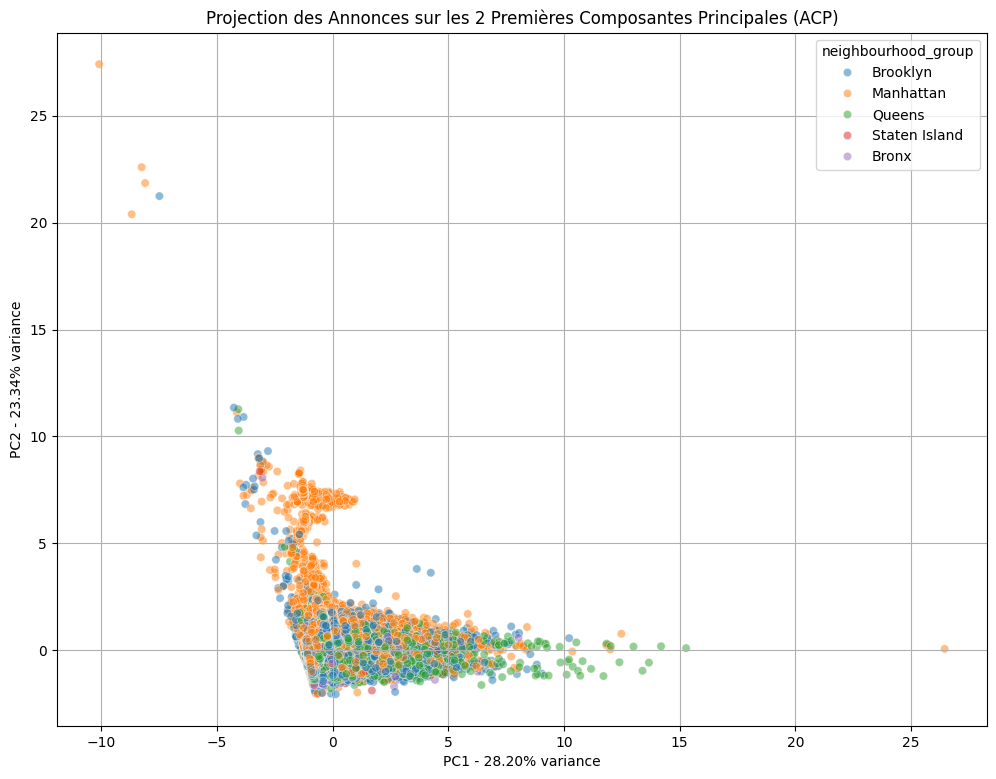

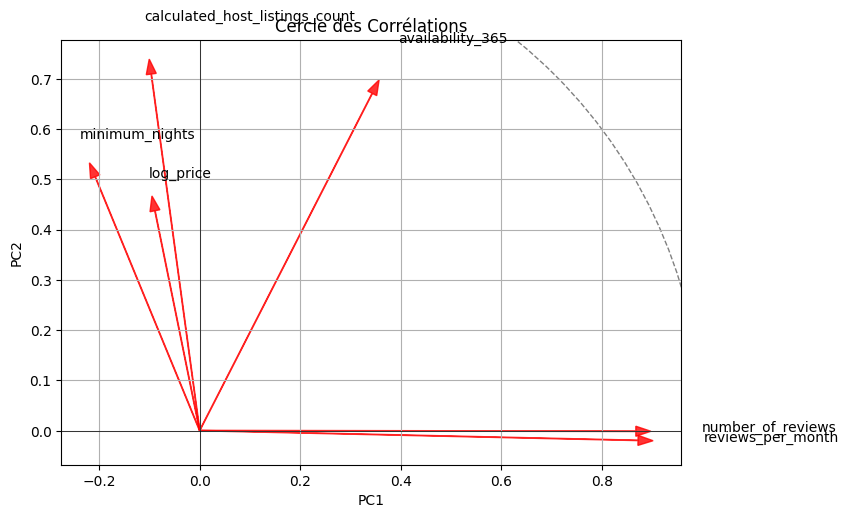


--- Lancement de l'ACM ---


"mca = prince.MCA(n_components=2, n_iter=3, random_state=42)\nmca = mca.fit(df_mca_input)\n\n# CORRECTION #2 : La librairie prince utilise Altair. La syntaxe pour le titre change.\nchart = mca.plot(df_mca_input)\nchart = chart.properties(\n    title='Projection des Modalités sur le Premier Plan Factoriel (ACM)'\n)\nax = mca.plot(df_mca_input)\nplt.show()"

In [ ]:
# PARTIE 4 : RÉDUCTION DE DIMENSION (Leçons 3-4-5) - CORRIGÉ #2
print("\n--- Étape 4: Réduction de Dimension ---")

# 1. Analyse en Composantes Principales (ACP) sur les données numériques
print("--- Lancement de l'ACP ---")
features_for_pca = ['log_price', 'minimum_nights', 'number_of_reviews', 
                      'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

# Centrer et réduire les données est CRUCIAL pour l'ACP
X = df_clean[features_for_pca].values
X_scaled = StandardScaler().fit_transform(X)

# Application de l'ACP
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)
df_pca = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])

# Ajout des informations qualitatives pour la visualisation
df_pca.index = df_clean.index
df_pca['neighbourhood_group'] = df_clean['neighbourhood_group']

# Visualisation des individus sur le premier plan factoriel
plt.figure(figsize=(12, 9))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='neighbourhood_group', alpha=0.5)
plt.title('Projection des Annonces sur les 2 Premières Composantes Principales (ACP)')
plt.xlabel(f'PC1 - {pca.explained_variance_ratio_[0]*100:.2f}% variance')
plt.ylabel(f'PC2 - {pca.explained_variance_ratio_[1]*100:.2f}% variance')
plt.grid(True)
plt.show()

# Cercle des corrélations (Interprétation des axes)
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
fig, ax = plt.subplots(figsize=(8, 8))
for i, feature in enumerate(features_for_pca):
    ax.arrow(0, 0, loadings[i,0], loadings[i,1], color='r', alpha=0.8, head_width=0.02)
    ax.text(loadings[i,0]*1.15, loadings[i,1]*1.15, feature, color='black')
circle = plt.Circle((0,0), 1, color='gray', fill=False, linestyle='--')
ax.add_artist(circle)
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('Cercle des Corrélations')
ax.set_aspect('equal', adjustable='box')
ax.grid(True)
plt.show()

# 2. Analyse des Correspondances Multiples (ACM) sur les données catégorielles
print("\n--- Lancement de l'ACM ---")
df_clean['price_category'] = pd.qcut(df_clean['price'], q=3, labels=['Bas', 'Moyen', 'Élevé'])
features_for_mca = ['neighbourhood_group', 'room_type', 'price_category']
df_mca_input = df_clean[features_for_mca]

'''mca = prince.MCA(n_components=2, n_iter=3, random_state=42)
mca = mca.fit(df_mca_input)

# CORRECTION #2 : La librairie prince utilise Altair. La syntaxe pour le titre change.
chart = mca.plot(df_mca_input)
chart = chart.properties(
    title='Projection des Modalités sur le Premier Plan Factoriel (ACM)'
)
ax = mca.plot(df_mca_input)
plt.show()'''


--- Étape 5: Clustering ---
--- Lancement du K-Means ---


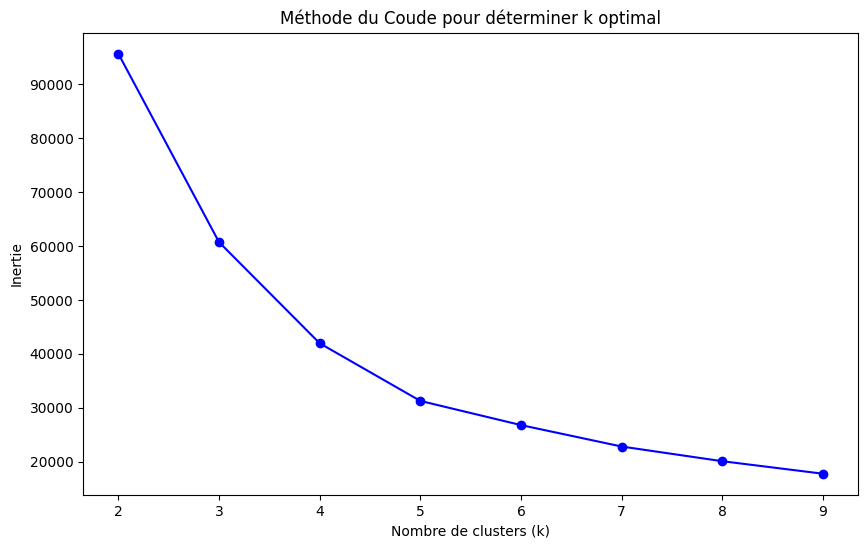

Clustering K-Means avec k=4 terminé.


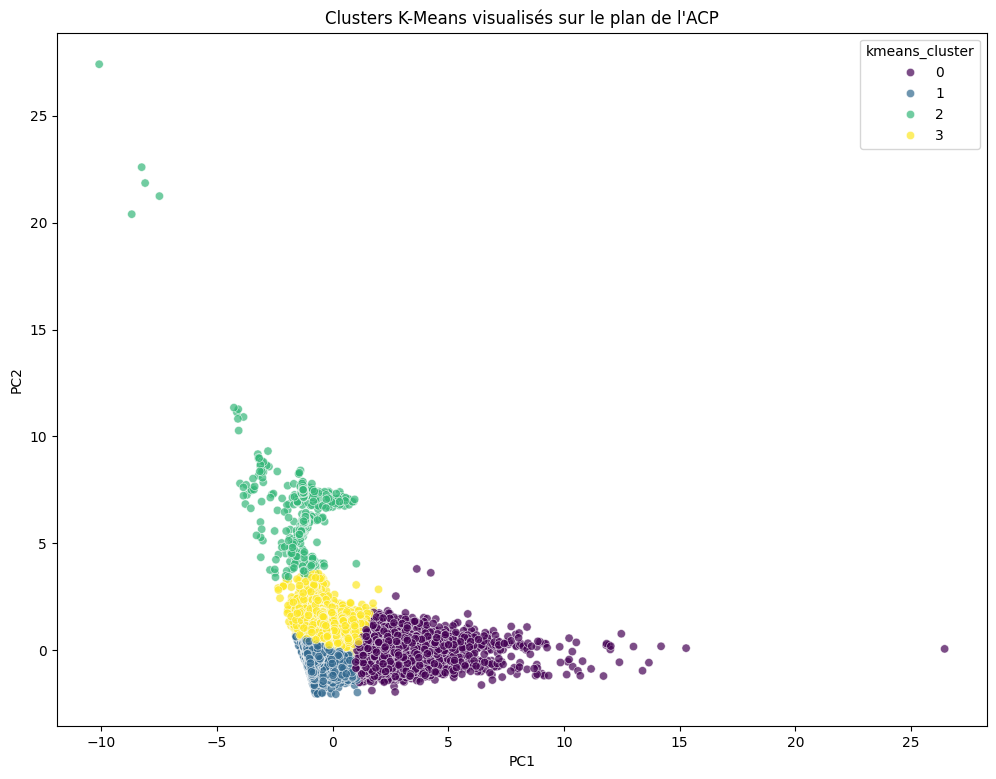

Profil moyen des clusters (sur données non-standardisées) :
                log_price  minimum_nights  number_of_reviews  \
kmeans_cluster                                                 
0                4.601097        2.417487          95.962565   
1                4.620543        4.371628           8.102000   
2                5.459802       64.369705           2.888318   
3                4.956670       12.391522          13.784061   

                reviews_per_month  calculated_host_listings_count  \
kmeans_cluster                                                      
0                        3.834949                        2.143005   
1                        0.494279                        1.514521   
2                        0.551772                      222.657253   
3                        0.776672                        9.744214   

                availability_365  
kmeans_cluster                    
0                     166.906347  
1                      25.828956  


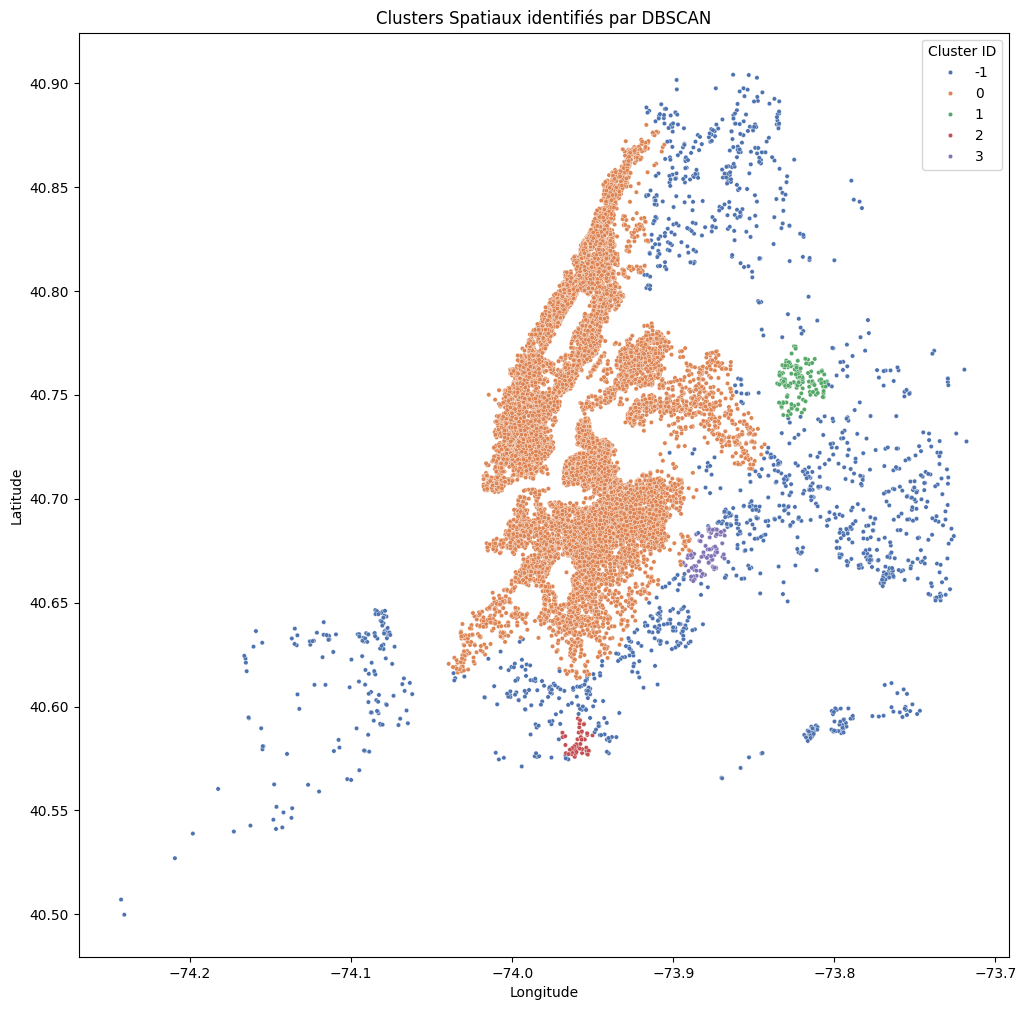

In [20]:
# =============================================================================
# PARTIE 5 : CLUSTERING (Leçon 6)
# =============================================================================
print("\n--- Étape 5: Clustering ---")

# 1. K-Means sur les composantes principales de l'ACP
print("--- Lancement du K-Means ---")
# On utilise les données de l'ACP pour le clustering
X_for_kmeans = df_pca[['PC1', 'PC2']].values

# Détermination du nombre optimal de clusters (Méthode du coude)
inertia = []
K_range = range(2, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_for_kmeans)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(K_range, inertia, 'bo-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Inertie')
plt.title('Méthode du Coude pour déterminer k optimal')
plt.show()

# On choisit k=4 (un coude visible)
k_optimal = 4
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
df_pca['kmeans_cluster'] = kmeans.fit_predict(X_for_kmeans)
print(f"Clustering K-Means avec k={k_optimal} terminé.")

# Visualisation des clusters K-Means
plt.figure(figsize=(12, 9))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='kmeans_cluster', palette='viridis', alpha=0.7)
plt.title('Clusters K-Means visualisés sur le plan de l\'ACP')
plt.show()

# Interprétation des clusters
cluster_profile = df_clean.join(df_pca['kmeans_cluster'])
print("Profil moyen des clusters (sur données non-standardisées) :")
print(cluster_profile.groupby('kmeans_cluster')[numerical_cols].mean())


# 2. DBSCAN pour le clustering spatial
print("\n--- Lancement du DBSCAN ---")
# On prend un échantillon pour des raisons de performance
df_sample_spatial = df_clean.sample(n=20000, random_state=42)
coords = df_sample_spatial[['latitude', 'longitude']].values

# Les paramètres eps et min_samples sont cruciaux et nécessitent des tests.
# eps=0.01 (environ 1km à NYC), min_samples=50
dbscan = DBSCAN(eps=0.01, min_samples=50)
df_sample_spatial['dbscan_cluster'] = dbscan.fit_predict(coords)
print("Clustering spatial DBSCAN terminé.")
print(f"Nombre de clusters trouvés : {df_sample_spatial['dbscan_cluster'].nunique() - 1}")
print(f"Nombre de points 'bruit' (outliers) : {(df_sample_spatial['dbscan_cluster'] == -1).sum()}")


# Visualisation des clusters DBSCAN
plt.figure(figsize=(12, 12))
sns.scatterplot(data=df_sample_spatial, x='longitude', y='latitude', 
                hue='dbscan_cluster', palette='deep', s=10, 
                legend='full')
plt.title('Clusters Spatiaux identifiés par DBSCAN')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Cluster ID')
plt.show()

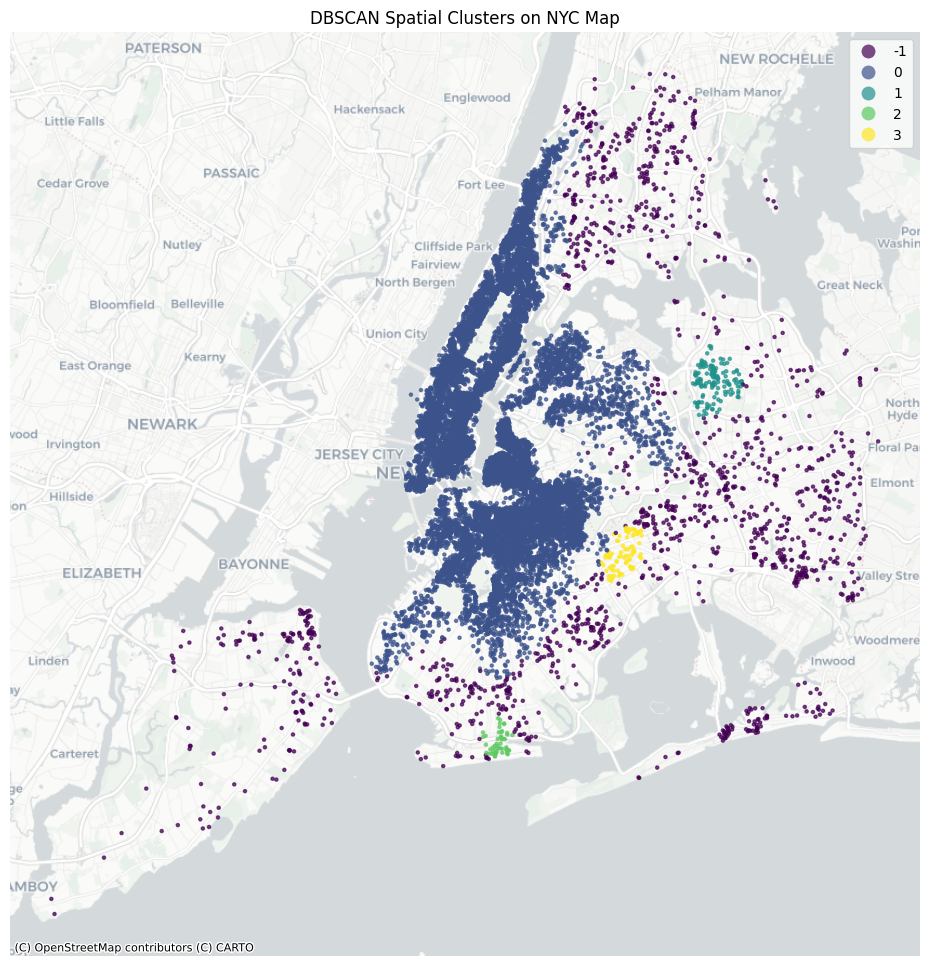

In [32]:
import geopandas as gpd
import contextily as ctx

gdf_spatial = gpd.GeoDataFrame(
    df_sample_spatial,
    geometry=gpd.points_from_xy(df_sample_spatial.longitude, df_sample_spatial.latitude),
    crs="EPSG:4326"
).to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 12))
gdf_spatial.plot(
    ax=ax,
    column='dbscan_cluster',
    categorical=True,
    cmap='viridis',
    markersize= 5,
    alpha=0.7,
    legend=True
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)
ax.set_axis_off()
plt.title('DBSCAN Spatial Clusters on NYC Map')
plt.show()

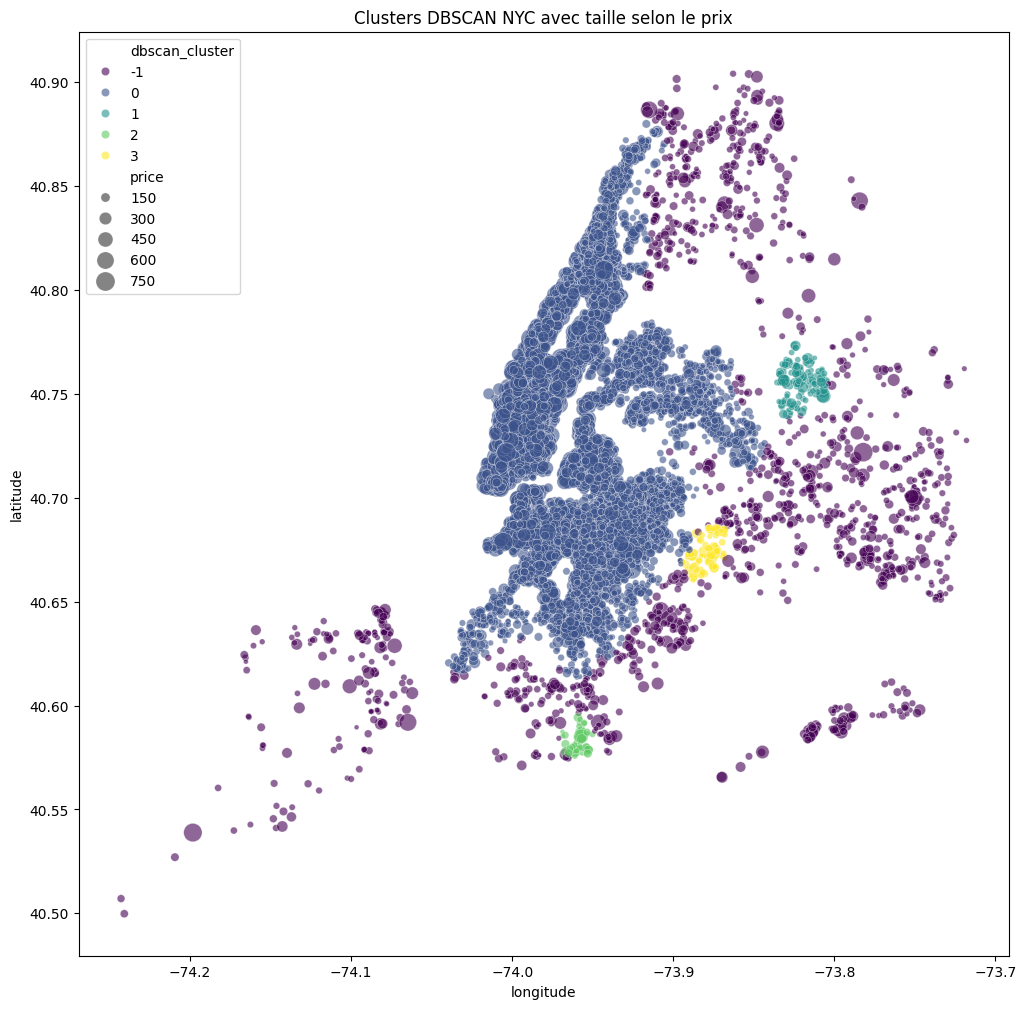

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,12))
sns.scatterplot(
    data=df_sample_spatial,
    x='longitude',
    y='latitude',
    hue='dbscan_cluster',     # couleur par cluster
    size='price',             # taille des points selon le prix
    sizes=(10, 200),          # min et max de taille en points
    alpha=0.6,
    palette='viridis'
)
plt.title('Clusters DBSCAN NYC avec taille selon le prix')
plt.show()


In [21]:
# =============================================================================
# PARTIE 6 : SYNTHÈSE ET CONCLUSION
# =============================================================================
print("\n--- Étape 6: Synthèse et Conclusion ---")

# Cette partie est rédactionnelle. Utilisez les résultats ci-dessus pour répondre.
# Voici un exemple de ce que vous pourriez écrire dans une cellule Markdown.
conclusion_text = """
## Synthèse des Résultats

### 1. Structure du Marché
L'analyse statistique a confirmé que les prix varient **significativement** entre les arrondissements, Manhattan étant le plus cher. Le marché est dominé par les offres à Brooklyn et Manhattan, avec une forte association entre 'Manhattan' et le type de logement 'Entire home/apt'.

### 2. Facteurs Latents (ACP & ACM)
L'**ACP** a révélé deux axes majeurs :
- **PC1** oppose les logements à forte activité commerciale (disponibilité élevée, beaucoup de reviews, plusieurs listings) aux locations plus occasionnelles.
- **PC2** semble discriminer les logements sur la base du `minimum_nights`.
L'**ACM** a visuellement confirmé les liens forts entre les modalités 'Manhattan', 'Entire home/apt' et la catégorie de prix 'Élevé'.

### 3. Segmentation (Clustering)
- Le **K-Means** a permis de créer 4 profils d'annonces distincts, par exemple un cluster "luxe peu disponible" et un autre "business à fort volume".
- Le **DBSCAN** a redéfini la géographie de NYC non pas par ses frontières administratives, mais par la **densité réelle des offres**. On a pu identifier des "hotspots" très concentrés (ex: Midtown, Williamsburg) et des zones plus diffuses.

### Conclusion Générale
La problématique était de voir s'il existait des "sous-marchés" à NYC. La réponse est **oui**. Ces sous-marchés ne sont pas seulement définis par l'arrondissement, mais par une combinaison de **style de gestion** (professionnel vs. occasionnel, révélé par l'ACP), de **type de bien** et de **micro-localisation géographique** (révélée par DBSCAN). Un investisseur devrait donc cibler non pas "Brooklyn", mais un certain *type de cluster DBSCAN* contenant un certain *profil d'annonce K-Means*.
"""
print(conclusion_text)


--- Étape 6: Synthèse et Conclusion ---

## Synthèse des Résultats

### 1. Structure du Marché
L'analyse statistique a confirmé que les prix varient **significativement** entre les arrondissements, Manhattan étant le plus cher. Le marché est dominé par les offres à Brooklyn et Manhattan, avec une forte association entre 'Manhattan' et le type de logement 'Entire home/apt'.

### 2. Facteurs Latents (ACP & ACM)
L'**ACP** a révélé deux axes majeurs :
- **PC1** oppose les logements à forte activité commerciale (disponibilité élevée, beaucoup de reviews, plusieurs listings) aux locations plus occasionnelles.
- **PC2** semble discriminer les logements sur la base du `minimum_nights`.
L'**ACM** a visuellement confirmé les liens forts entre les modalités 'Manhattan', 'Entire home/apt' et la catégorie de prix 'Élevé'.

### 3. Segmentation (Clustering)
- Le **K-Means** a permis de créer 4 profils d'annonces distincts, par exemple un cluster "luxe peu disponible" et un autre "business à fort vol